# L2.2 · Plan cash for an ATM

**PowerPoint slides** 16–20  
**Course data** atm_cash_daily.csv

### The problem

How much cash should we plan for when customers may withdraw different amounts on different days?

### What this demo shows

Use last week’s withdrawals as a simple guess. Then read a prepared table that compares that guess with a few models. Also look at P90, a higher forecast for planning.

### Why we’re doing it

We want a guess we can explain. We also want to understand how a higher planned cash amount can reduce shortfalls and leave more unused cash.

**If this is your first ML activity**, open [00 · Your first ML workflow](00_Start_Here_Your_First_ML_Workflow.ipynb) first. For the simpler examples of model types and repeated checking, see [01 · Regression and classification](01_Regression_and_Classification.ipynb) and [03 · K-fold cross-validation](03_K_Fold_Cross_Validation.ipynb).

Here, read the plain-English explanation before each cell. Run **Setup**, then work down the page with **Shift + Enter**.

## Setup · Load the data

Use ATM100’s daily rows from July through October 2025. Keep the original readings available for comparison. The first few lines locate the course data folder. You can
run the whole cell as written.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

working_folder = Path.cwd()
data_folder = next(
    (folder / 'data' for folder in (working_folder, *working_folder.parents)
     if (folder / 'data' / 'property_valuations.csv').is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError('Open the extracted course folder in Jupyter or VS Code.')

columns = ["date", "atm_id", "withdrawal_aed", "is_weekend", "weekend_regime", "is_payday_window"]
cash = pd.read_csv(data_folder / "atm_cash_daily.csv", usecols=columns, parse_dates=["date"])
atm = cash[cash["atm_id"] == "ATM100"].sort_values("date").set_index("date")
recent = atm.loc["2025-07-01":].copy()
display(recent.head(3))

,atm_id,withdrawal_aed,is_payday_window,weekend_regime,is_weekend
date,,,,,
2025-07-01,ATM100,62400.0,1,Sat-Sun,0
2025-07-02,ATM100,57700.0,1,Sat-Sun,0
2025-07-03,ATM100,53600.0,0,Sat-Sun,0


## 1 · Find and fill a gap

**What we’re doing.** Find a missing ATM reading. Keep a marker and copy the last recorded amount into the gap.

**Why we’re doing it.** A missing reading tells us we lack a record. Copying an earlier value provides a temporary input and keeps the fact that we filled it visible.

**What to look for.** The gap marker stays visible and the fill repeats the previous amount.

In [2]:
actual = recent["withdrawal_aed"]
repair = pd.DataFrame({"Original": actual, "Missing?": actual.isna(), "Past-only fill": actual.ffill()})
first_gap = repair.index[repair["Missing?"]][0]
display(repair.loc[first_gap - pd.Timedelta(days=1):first_gap + pd.Timedelta(days=1)])

,Original,Missing?,Past-only fill
date,,,
2025-07-04,53600.0,False,53600.0
2025-07-05,NaN,True,53600.0
2025-07-06,62800.0,False,62800.0


## 2 · Forecast with last week’s amounts

**What we’re doing.** Copy the seven recorded amounts just before the cutoff as guesses for the next seven days.

**Why we’re doing it.** A week often repeats a pattern. This gives us a simple guess that only uses numbers available when we make a plan.

**What to look for.** The seven guesses come from October 11–17. The first date being forecast is October 18.

In [3]:
history = actual.iloc[:-14].ffill()
next_week = actual.iloc[-14:-7]
repeat_week = pd.Series(history.tail(7).tolist(), index=next_week.index)
missed_by = (next_week - repeat_week).abs()
display(pd.DataFrame({"Actual AED": next_week, "Predicted AED": repeat_week, "Absolute error": missed_by}))
print(f"Mean absolute error: AED {missed_by.mean():,.0f}")

,Actual AED,Predicted AED,Absolute error
date,,,
2025-10-18,55300.0,59900.0,4600.0
2025-10-19,58700.0,51700.0,7000.0
2025-10-20,49500.0,58700.0,9200.0
2025-10-21,62100.0,61200.0,900.0
2025-10-22,57800.0,49200.0,8600.0
2025-10-23,56400.0,51600.0,4800.0
2025-10-24,63800.0,65400.0,1600.0


Mean absolute error: AED 5,243


## 3 · Build inputs for a seven-day forecast

**What we’re doing.** Show two older amounts, an average of older amounts, and a weekend flag.

**Why we’re doing it.** We want clues that exist at least seven days before the amount we are forecasting. The future weekday can also be looked up in a calendar.

**What to look for.** Locate the value seven days before the target. The rolling average ends at that date.

In [4]:
available = actual.ffill()
features = pd.DataFrame({
    "7 days ago": available.shift(7),
    "14 days ago": available.shift(14),
    "Earlier week average": available.shift(7).rolling(7).mean(),
    "Weekend at target": recent["is_weekend"],
})
display(features.iloc[14:18].round(0))

,7 days ago,14 days ago,Earlier week average,Weekend at target
date,,,,
2025-07-15,50300.0,62400.0,53129.0,0
2025-07-16,47200.0,57700.0,51629.0,0
2025-07-17,53400.0,53600.0,51600.0,0
2025-07-18,53100.0,53600.0,51529.0,0


## 4 · Compare prepared forecasts

**What we’re doing.** Compare forecasts from the same ATM100 training
history, which ends on **October 17, 2025**. This table shows the next
seven observed days. The full course lab applies these methods over
longer periods and across the ATM network.

**Why we’re doing it.** A method can use last week’s amounts, a repeating pattern or extra clues from the calendar. Reading these guesses side by side helps us see how the approaches differ.

| Method | What it uses |
|---|---|
| Repeat last week | The seven observed amounts before the cutoff. |
| Holt–Winters | Smoothing with a trend and a repeating seven-day pattern. |
| SARIMAX | The series’ past and calendar inputs. This small example uses an autoregressive term, weekend and payday flags. |
| Linear model | A weighted combination of past amounts and calendar flags. |
| Gradient boosting | Several small trees trained in sequence using the same inputs. |
| P90 gradient boosting | The same inputs with a training loss that targets the 90th percentile. |

The linear and tree models use the seven-day lag, fourteen-day lag,
shifted weekly mean, weekend flag and payday flag. Every input in the
displayed week was available by the forecast cutoff. The fits were
prepared ahead of class. The short cell builds the results table so
you can focus on the numbers.

In [5]:
forecasts = pd.DataFrame({
    'Date': ['2025-10-18', '2025-10-19', '2025-10-20', '2025-10-21', '2025-10-22', '2025-10-23', '2025-10-24'],
    'Actual': [55300, 58700, 49500, 62100, 57800, 56400, 63800],
    'Repeat last week': [59900, 51700, 58700, 61200, 49200, 51600, 65400],
    'Holt–Winters': [56006, 48916, 53682, 57100, 54329, 55906, 60267],
    'SARIMAX + calendar': [91808, 83323, 36526, 34093, 32790, 32092, 31718],
    'Linear model': [55200, 49748, 52888, 54985, 51967, 54614, 59344],
    'Gradient boosting': [59209, 48628, 51257, 55624, 53188, 56542, 63258],
    'P90 gradient boosting': [61446, 60302, 60227, 61314, 60899, 70169, 66788],
}).set_index('Date')
display(forecasts)

,Actual,Repeat last week,Holt–Winters,SARIMAX + calendar,Linear model,Gradient boosting,P90 gradient boosting
Date,,,,,,,
2025-10-18,55300,59900,56006,91808,55200,59209,61446
2025-10-19,58700,51700,48916,83323,49748,48628,60302
2025-10-20,49500,58700,53682,36526,52888,51257,60227
2025-10-21,62100,61200,57100,34093,54985,55624,61314
2025-10-22,57800,49200,54329,32790,51967,53188,60899
2025-10-23,56400,51600,55906,32092,54614,56542,70169
2025-10-24,63800,65400,60267,31718,59344,63258,66788


## 5 · Compare the point forecasts

**What we’re doing.** Find the typical AED miss for each method that makes a single estimate of cash demand.

**Why we’re doing it.** Every method is checked on the same dates. That makes it easier to see which guess did better on these days.

**What to look for.** Find the smallest error, then check whether it improved on repeating last week for this sample.

In [6]:
point_forecasts = forecasts.drop(columns=["Actual", "P90 gradient boosting"])
misses = point_forecasts.sub(forecasts["Actual"], axis=0).abs()
display(misses.mean().round(0).sort_values().rename("MAE in AED"))

Holt–Winters           3881.0
Gradient boosting      3930.0
Linear model           4519.0
Repeat last week       5243.0
SARIMAX + calendar    26216.0
Name: MAE in AED, dtype: float64

## 6 · Use P90 to discuss a cash plan

**What we’re doing.** Count the days when actual withdrawals stayed at or below the P90 forecast.

**Why we’re doing it.** A higher forecast can leave enough cash for more days. Counting the days covered and the cash shortfall helps us discuss the trade-off.

**What to look for.** These seven days illustrate how we would assess coverage. Many more forecast origins are needed to estimate it.

In [7]:
p90 = forecasts["P90 gradient boosting"]
covered = forecasts["Actual"] <= p90
shortfall = (forecasts["Actual"] - p90).clip(lower=0)
print(f"Days covered: {covered.sum()} of {len(covered)}")
print(f"Total shortfall: AED {shortfall.sum():,.0f}")

Days covered: 6 of 7
Total shortfall: AED 786


### See days when P90 covers the actual withdrawals

Follow the blue actual line and amber P90 line. A blue point above the amber line is a day when this planned amount would have run short.

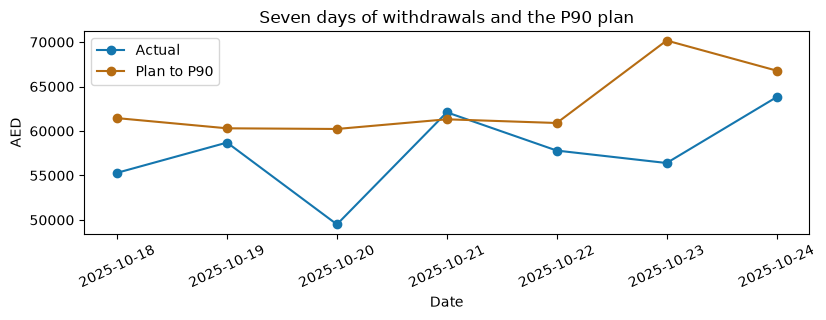

In [8]:
import matplotlib.pyplot as plt

chart = forecasts[["Actual", "P90 gradient boosting"]].rename(columns={"P90 gradient boosting": "Plan to P90"})
ax = chart.plot(figsize=(8.4, 3.3), marker="o", color=["#1476ae", "#b66c12"], rot=25)
ax.set(title="Seven days of withdrawals and the P90 plan", xlabel="Date", ylabel="AED")
plt.tight_layout()
plt.show()

### Your turn

Pick one date in step 4. Compare actual cash demand with the point
forecast and P90 for that day. Which choice would have left extra cash
and which would have run short?